In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Project folder:", PROJECT_ROOT)
print("Data folder exists:", RAW_DIR.exists())
print("CSV files:", sorted(p.name for p in RAW_DIR.glob("*.csv")))

Project folder: /Users/celestine/Desktop/intern/Customer Churn Project/kkbox-churn-prediction
Data folder exists: True
CSV files: ['members_v3.csv', 'train.csv', 'train_v2.csv']


In [2]:
train = pd.read_csv(RAW_DIR / "train.csv")
train_v2 = pd.read_csv(RAW_DIR / "train_v2.csv")

print("train shape:", train.shape)
print("train_v2 shape:", train_v2.shape)

train.head()

train shape: (992931, 2)
train_v2 shape: (970960, 2)


,msno,is_churn
0,waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=,1
1,QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq2OxDr8zqa7bRQ=,1
2,fGwBva6hikQmTJzrbz/2Ezjm5Cth5jZUNvXigKK2AFA=,1
3,mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=,1
4,XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=,1


In [3]:
def audit_labels(df):
    return pd.Series({
        "rows": len(df),
        "unique_users": df["msno"].nunique(),
        "missing_user_ids": df["msno"].isna().sum(),
        "duplicate_user_rows": df["msno"].duplicated().sum(),
        "missing_labels": df["is_churn"].isna().sum(),
        "invalid_labels": (
            df["is_churn"].notna()
            & ~df["is_churn"].isin([0, 1])
        ).sum(),
        "churn_rate": df["is_churn"].mean(),
    })

label_audit = pd.DataFrame({
    "train": audit_labels(train),
    "train_v2": audit_labels(train_v2),
}).T

label_audit

,rows,unique_users,missing_user_ids,duplicate_user_rows,missing_labels,invalid_labels,churn_rate
train,992931.0,992931.0,0.0,0.0,0.0,0.0,0.063923
train_v2,970960.0,970960.0,0.0,0.0,0.0,0.0,0.089942


In [4]:
train_users = set(train["msno"])
v2_users = set(train_v2["msno"])

shared_users = train_users & v2_users

overlap_summary = pd.Series({
    "shared_users": len(shared_users),
    "only_in_train": len(train_users - v2_users),
    "only_in_train_v2": len(v2_users - train_users),
    "share_of_train": len(shared_users) / len(train_users),
    "share_of_train_v2": len(shared_users) / len(v2_users),
})

overlap_summary

shared_users         881701.000000
only_in_train        111230.000000
only_in_train_v2      89259.000000
share_of_train            0.887978
share_of_train_v2         0.908071
dtype: float64

In [5]:
shared_labels = train.merge(
    train_v2,
    on="msno",
    how="inner",
    suffixes=("_train", "_v2"),
    validate="one_to_one",
)

label_comparison = pd.crosstab(
    shared_labels["is_churn_train"],
    shared_labels["is_churn_v2"],
    rownames=["train label"],
    colnames=["train_v2 label"],
)

label_comparison

train_v2 label,0,1
train label,,
0,824659,40721
1,5269,11052


### Initial label audit

- `train.csv` contains 992,931 users, with a churn rate of 6.39%.
- `train_v2.csv` contains 970,960 users, with a churn rate of 8.99%.
- Neither label table contains missing user IDs, duplicate user IDs, missing labels, or invalid labels.
- The two tables share 881,701 users. Among these users, 45,990 (5.22%) have different labels across versions.
- The label periods and feature cutoffs must be verified before combining the tables or designing temporal validation.

In [6]:
members_path = RAW_DIR / "members_v3.csv"

members_preview = pd.read_csv(members_path, nrows=5)

print("Columns:", members_preview.columns.tolist())
members_preview

Columns: ['msno', 'city', 'bd', 'gender', 'registered_via', 'registration_init_time']


,msno,city,bd,gender,registered_via,registration_init_time
0,Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8=,1,0,NaN,11,20110911
1,+tJonkh+O1CA796Fm5X60UMOtB6POHAwPjbTRVl/EuU=,1,0,NaN,7,20110914
2,cV358ssn7a0f7jZOwGNWS07wCKVqxyiImJUX6xcIwKw=,1,0,NaN,11,20110915
3,9bzDeJP6sQodK73K5CBlJ6fgIQzPeLnRl0p5B77XP+g=,1,0,NaN,11,20110915
4,WFLY3s7z4EZsieHCt63XrsdtfTEmJ+2PnnKLH5GY4Tk=,6,32,female,9,20110915


In [7]:
import duckdb

con = duckdb.connect()

members_audit = con.execute(
    """
    SELECT
        COUNT(*) AS rows,
        COUNT(DISTINCT msno) AS unique_users,
        COUNT(*) FILTER (
            WHERE msno IS NULL OR TRIM(msno) = ''
        ) AS missing_user_ids
    FROM read_csv(?, all_varchar = true)
    """,
    [str(members_path)],
).df()

members_audit

,rows,unique_users,missing_user_ids
0,6769473,6769473,0


In [8]:
con.register("labels_v2", train_v2)

con.read_csv(
    str(members_path),
    all_varchar=True,
).create_view("members_raw")

┌──────────────────────────────────────────────┬─────────┬─────────┬─────────┬────────────────┬────────────────────────┐
│                     msno                     │  city   │   bd    │ gender  │ registered_via │ registration_init_time │
│                   varchar                    │ varchar │ varchar │ varchar │    varchar     │        varchar         │
├──────────────────────────────────────────────┼─────────┼─────────┼─────────┼────────────────┼────────────────────────┤
│ Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8= │ 1       │ 0       │ NULL    │ 11             │ 20110911               │
│ +tJonkh+O1CA796Fm5X60UMOtB6POHAwPjbTRVl/EuU= │ 1       │ 0       │ NULL    │ 7              │ 20110914               │
│ cV358ssn7a0f7jZOwGNWS07wCKVqxyiImJUX6xcIwKw= │ 1       │ 0       │ NULL    │ 11             │ 20110915               │
│ 9bzDeJP6sQodK73K5CBlJ6fgIQzPeLnRl0p5B77XP+g= │ 1       │ 0       │ NULL    │ 11             │ 20110915               │
│ WFLY3s7z4EZsieHCt63XrsdtfTEmJ+

In [19]:
member_coverage = con.execute(
    (PROJECT_ROOT / "sql" / "member_coverage.sql").read_text(
        encoding="utf-8"
    )
).df()

member_coverage

,label_users,matched_users,unmatched_users,matched_pct
0,970960,860967,109993,88.67


In [10]:
member_quality = con.execute("""
    WITH matched AS (
        SELECT
            TRY_CAST(m.bd AS INTEGER) AS age,
            NULLIF(TRIM(m.gender), '') AS gender
        FROM labels_v2 AS l
        INNER JOIN members_raw AS m
            ON l.msno = m.msno
    )
    SELECT
        COUNT(*) AS matched_users,
        COUNT(*) FILTER (WHERE age IS NULL) AS age_missing_or_unreadable,
        COUNT(*) FILTER (WHERE age = 0) AS age_zero,
        COUNT(*) FILTER (WHERE age < 0) AS age_negative,
        COUNT(*) FILTER (WHERE age > 100) AS age_over_100,
        MIN(age) AS min_age,
        MAX(age) AS max_age,
        COUNT(*) FILTER (WHERE gender IS NULL) AS gender_missing
    FROM matched
""").df()

member_quality

,matched_users,age_missing_or_unreadable,age_zero,age_negative,age_over_100,min_age,max_age,gender_missing
0,860967,0,473729,69,454,-3152,2016,472062


In [11]:
member_features_v2 = con.execute("""
    WITH joined AS (
        SELECT
            l.msno,
            l.is_churn,
            CAST(m.msno IS NOT NULL AS INTEGER) AS has_member,
            TRY_CAST(m.bd AS INTEGER) AS age_raw,
            NULLIF(TRIM(m.gender), '') AS gender_raw,
            m.city,
            m.registered_via
        FROM labels_v2 AS l
        LEFT JOIN members_raw AS m
            ON l.msno = m.msno
    )
    SELECT
        msno,
        is_churn,
        has_member,
        CASE
            WHEN age_raw BETWEEN 1 AND 100 THEN age_raw
            ELSE NULL
        END AS age,
        CASE
            WHEN age_raw BETWEEN 1 AND 100 THEN 0
            ELSE 1
        END AS age_unusable,
        COALESCE(LOWER(gender_raw), 'unknown') AS gender,
        city,
        registered_via
    FROM joined
""").df()

print("Feature table shape:", member_features_v2.shape)

Feature table shape: (970960, 8)


In [12]:
assert len(member_features_v2) == len(train_v2)
assert member_features_v2["msno"].is_unique

usable_ages = member_features_v2["age"].dropna()
assert usable_ages.between(1, 100).all()

cleaning_summary = pd.Series({
    "total_users": len(member_features_v2),
    "users_without_member_info": (
        member_features_v2["has_member"] == 0
    ).sum(),
    "users_with_unusable_age": (
        member_features_v2["age_unusable"] == 1
    ).sum(),
    "users_with_unknown_gender": (
        member_features_v2["gender"] == "unknown"
    ).sum(),
})

cleaning_summary

total_users                  970960
users_without_member_info    109993
users_with_unusable_age      584245
users_with_unknown_gender    582055
dtype: int64

### Member Record Coverage and Churn

Compare churn rates between users with and without member records
to assess whether missing member information is associated with churn.

In [13]:
coverage_segments = (
    member_features_v2
    .groupby("has_member")
    .agg(
        users=("is_churn", "size"),
        churned_users=("is_churn", "sum"),
        churn_rate=("is_churn", "mean"),
    )
    .reset_index()
)

coverage_segments["segment"] = coverage_segments["has_member"].map({
    0: "No member record",
    1: "Member record available",
})

coverage_segments[
    ["segment", "users", "churned_users", "churn_rate"]
]

,segment,users,churned_users,churn_rate
0,No member record,109993,5882,0.053476
1,Member record available,860967,81448,0.094601


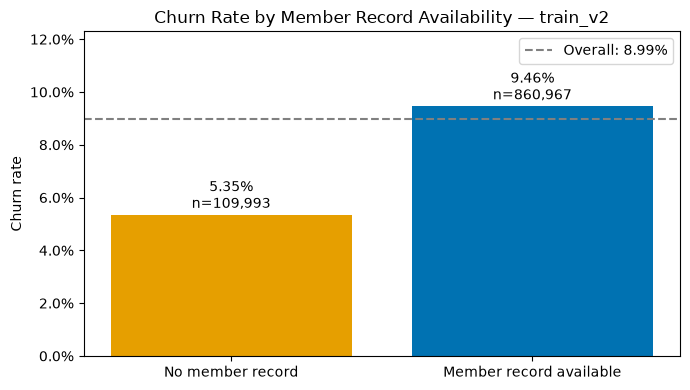

In [16]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

overall_rate = member_features_v2["is_churn"].mean()

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    coverage_segments["segment"],
    coverage_segments["churn_rate"],
    color=["#E69F00", "#0072B2"],
)

ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"Overall: {overall_rate:.2%}",
)

for bar, row in zip(bars, coverage_segments.itertuples(index=False)):
    ax.annotate(
        f"{row.churn_rate:.2%}\nn={row.users:,}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(
    0,
    max(coverage_segments["churn_rate"].max(), overall_rate) * 1.3,
)
ax.set_ylabel("Churn rate")
ax.set_title("Churn Rate by Member Record Availability — train_v2")
ax.legend()

fig.tight_layout()

figure_dir = PROJECT_ROOT / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "churn_by_member_availability.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

### Findings and Implications

In `train_v2`, 109,993 users (11.33%) have no matching member record. Their churn rate is 5.35%, compared with 9.46% among users with member records—a difference of approximately 4.11 percentage points.

Dropping unmatched users would change the sample composition and increase the observed churn rate from 8.99% to 9.46%. We therefore retain all labeled users and include a `has_member` indicator.

This is a descriptive association, not evidence that member record availability causes churn. The indicator's predictive value must be evaluated on held-out data.

Unusable ages are treated as missing, and missing gender values are represented as `unknown`. Label periods and feature availability must be verified before modeling.

In [17]:
report_dir = PROJECT_ROOT / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

label_audit.to_csv(
    report_dir / "label_audit.csv",
    index_label="dataset",
)

member_coverage.to_csv(
    report_dir / "member_coverage.csv",
    index=False,
)

member_quality.to_csv(
    report_dir / "member_quality.csv",
    index=False,
)

cleaning_summary.rename("count").to_csv(
    report_dir / "cleaning_summary.csv",
    index_label="metric",
)

coverage_segments[
    ["segment", "users", "churned_users", "churn_rate"]
].to_csv(
    report_dir / "churn_by_member_availability.csv",
    index=False,
)

print("Audit reports saved.")

Audit reports saved.


In [18]:
coverage_sql = """
SELECT
    COUNT(*) AS label_users,
    COUNT(m.msno) AS matched_users,
    COUNT(*) - COUNT(m.msno) AS unmatched_users,
    ROUND(
        100.0 * COUNT(m.msno) / COUNT(*), 2
    ) AS matched_pct
FROM labels_v2 AS l
LEFT JOIN members_raw AS m
    ON l.msno = m.msno;
"""

sql_dir = PROJECT_ROOT / "sql"
sql_dir.mkdir(parents=True, exist_ok=True)

sql_path = sql_dir / "member_coverage.sql"
sql_path.write_text(coverage_sql.strip() + "\n", encoding="utf-8")

print("Saved:", sql_path)

Saved: /Users/celestine/Desktop/intern/Customer Churn Project/kkbox-churn-prediction/sql/member_coverage.sql
